In [34]:
import numpy as np
import scipy as sc
import matplotlib.pyplot as plt

## 3.6.4 c

In [49]:
lambd0 = 2/np.pi
x_vals = np.linspace(-1,1,101)
f0 = lambda x: np.zeros_like(x)
f1 = lambda x: x**2 
f2 = lambda x: np.cos(x)

In [50]:
def operator(f_vals, lamb):
    f_next = np.zeros_like(x_vals)
    for i, x in enumerate(x_vals):
        integrand = lambda y: np.interp(y, x_vals, f_vals) / (1 + (x-y)**2)
        integral = sc.integrate.quad(integrand, -1,1)
        f_next[i] = np.sin(2 * np.pi * x) + lamb * integral[0]
    return f_next

def fixed_point_iter(lamb, f_init, nmax=20):
    f_curr = f_init(x_vals)
    for k in range(1, nmax+1):
        f_next = operator(f_curr, lamb)
        diff = np.max(np.abs(f_next-f_curr))
        f_curr = f_next
        if k % 5 == 0 or k == 1:
            print(f"Iteration {k}: ||T(f)-f|| = {diff:.6e}")
    return f_curr

In [ ]:
# |lambda| < lambda_0
f_curr0 = fixed_point_iter(1/np.pi, f0)
f_curr1 = fixed_point_iter(1/np.pi, f1)
f_curr2 = fixed_point_iter(1/np.pi, f2)
# |lambda| > lambda_0
f_curr3 = fixed_point_iter(1, f0)
f_curr4 = fixed_point_iter(1, f1)
f_curr5 = fixed_point_iter(1, f2)

Iteration 1: ||T(f)-f|| = 9.980267e-01


C:\Users\madis\AppData\Local\Temp\ipykernel_180\60432662.py:5: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  integral = sc.integrate.quad(integrand, -1,1)


Iteration 5: ||T(f)-f|| = 8.151072e-05
Iteration 10: ||T(f)-f|| = 3.106681e-09
Iteration 15: ||T(f)-f|| = 1.184608e-13
Iteration 20: ||T(f)-f|| = 1.665335e-16


C:\Users\madis\AppData\Local\Temp\ipykernel_180\60432662.py:5: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  integral = sc.integrate.quad(integrand, -1,1)


Iteration 1: ||T(f)-f|| = 1.456788e+00
Iteration 5: ||T(f)-f|| = 7.751465e-03
Iteration 10: ||T(f)-f|| = 1.487605e-04
Iteration 15: ||T(f)-f|| = 2.855484e-06
Iteration 20: ||T(f)-f|| = 5.481151e-08
Iteration 1: ||T(f)-f|| = 1.544286e+00
Iteration 5: ||T(f)-f|| = 2.205712e-02
Iteration 10: ||T(f)-f|| = 4.233729e-04
Iteration 15: ||T(f)-f|| = 8.126719e-06
Iteration 20: ||T(f)-f|| = 1.559938e-07
Iteration 1: ||T(f)-f|| = 9.980267e-01
Iteration 5: ||T(f)-f|| = 7.939911e-03
Iteration 10: ||T(f)-f|| = 9.260760e-05
Iteration 15: ||T(f)-f|| = 1.080216e-06
Iteration 20: ||T(f)-f|| = 1.260012e-08
Iteration 1: ||T(f)-f|| = 1.373269e+00
Iteration 5: ||T(f)-f|| = 5.873931e-01
Iteration 10: ||T(f)-f|| = 3.448401e+00
Iteration 15: ||T(f)-f|| = 2.025627e+01
Iteration 20: ||T(f)-f|| = 1.189872e+02
Iteration 1: ||T(f)-f|| = 1.362113e+00
Iteration 5: ||T(f)-f|| = 1.670786e+00
Iteration 10: ||T(f)-f|| = 9.814070e+00
Iteration 15: ||T(f)-f|| = 5.764888e+01
Iteration 20: ||T(f)-f|| = 3.386362e+02


## 5

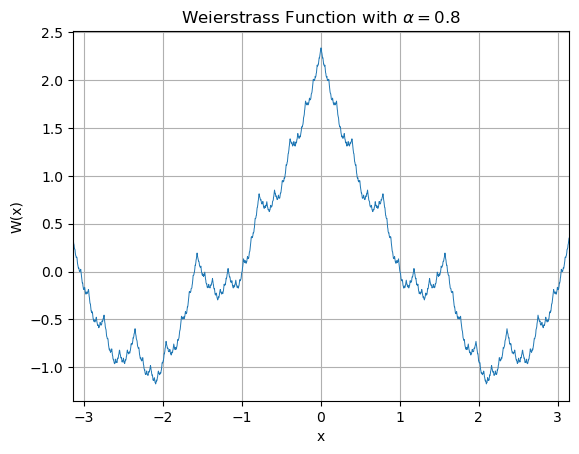

In [45]:
alpha = 0.8
n = 50
x = np.linspace(-np.pi, np.pi, 2000)
W = np.zeros_like(x)
for i in range(n):
    W += (2**(-i * alpha)) * np.cos((2**i) * x)

plt.plot(x, W, linewidth=0.7)
plt.title('Weierstrass Function with $\\alpha=0.8$')
plt.xlabel('x')
plt.ylabel('W(x)')
plt.xlim(-np.pi, np.pi)
plt.grid(True)